<a href="https://colab.research.google.com/github/asteriaji/MSSP6070/blob/main/Assignments/Assignment%202/Jiangyu_Ji_Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [47]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import statsmodels.formula.api as sm
import statsmodels.api as se
import seaborn as sns
import datetime as dt
from sklearn.linear_model import LinearRegression
from scipy import stats
from io import StringIO
import itertools
import os
import subprocess
from pathlib import Path

pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

owner = 'asteriaji'
repository = 'MSSP6070'
repo_url = f'https://github.com/{owner}/{repository}.git'
repo_path = Path('/content') / repository

if not repo_path.exists():
    subprocess.run(
        ['git', 'clone', repo_url, str(repo_path)],
        check=True
    )
else:
    print("Repository already exists. Using the existing copy.")

os.chdir(repo_path)
print("Current directory:", os.getcwd())

print("Files in repository:")
for item in sorted(repo_path.rglob('*')):
    if item.is_file() and '.git' not in item.parts:
        print(item.relative_to(repo_path))

Repository already exists. Using the existing copy.
Current directory: /content/MSSP6070
Files in repository:
Adding_File_Structure.py
Assignment_Template.ipynb
Assignments/.gitkeep
Assignments/Assignment 1/Corrected_Version_Jiangyu_Ji_MSSP_6070_Assignment_1.ipynb
Assignments/Assignment 1/Jiangyu_Ji_MSSP_6070_Assignment_1_260930.ipynb
Assignments/Assignment 2/1
WeeklyModules/.gitkeep
WeeklyModules/Week01/.gitkeep
WeeklyModules/Week01/1_introducing_matplotlib_(1).ipynb
WeeklyModules/Week01/Week1_Jiangyu_Ji_Participation_Activity_Exercises_260828.ipynb
WeeklyModules/Week01/stats_viz (1).py
WeeklyModules/Week02/.gitkeep
WeeklyModules/Week02/Week2_Jiangyu_Ji_Participation_Activity_260907__(2).ipynb
WeeklyModules/Week02/Week_2_Data_Stuctures.ipynb
WeeklyModules/Week03/.gitkeep
WeeklyModules/Week03/Week_3_Jiangyu_Ji_PARTICIPATION_ACTIVITY_(3)_(2).ipynb
WeeklyModules/Week04/.gitkeep
WeeklyModules/Week04/Jiangyu_Ji_Assignment_PARTICIPATION_ACTIVITY_Week_4_Opening_a_CSV_file_and_modifying_the_c

/tmp/ipykernel_1784/2443955387.py:17: Pandas4Warning: set_eng_float_format is deprecated and will be removed in a future version. Use pd.set_option('display.precision', N) to control decimal precision, or pass a custom callable to pd.set_option('display.float_format', func).
  pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)


In [48]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
DATA_PATH = repo_path /'data'/'Assignment 2'/'InternetSales (2).csv'

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Data file not found: {DATA_PATH}")

df = pd.read_csv(DATA_PATH,encoding="latin1")

print("Data loaded successfully!")
print("Data shape:", df.shape)
display(df.head())

Data loaded successfully!
Data shape: (60398, 60)


/tmp/ipykernel_1784/3147608290.py:11: DtypeWarning: Columns (14: Suffix) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(DATA_PATH,encoding="latin1")


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,LastName,NameStyle,BirthDate,MaritalStatus,Suffix,Gender,EmailAddress,YearlyIncome,TotalChildren,NumberChildrenAtHome,EnglishEducation,SpanishEducation,FrenchEducation,EnglishOccupation,SpanishOccupation,FrenchOccupation,HouseOwnerFlag,NumberCarsOwned,AddressLine1,AddressLine2,Phone,DateFirstPurchase,CommuteDistance,ProductKey,EnglishProductName,OrderDateKey,DueDateKey,ShipDateKey,CustomerKey.1,PromotionKey,CurrencyKey,SalesTerritoryKey,SalesOrderNumber,SalesOrderLineNumber,RevisionNumber,OrderQuantity,UnitPrice,ExtendedAmount,UnitPriceDiscountPct,DiscountAmount,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,False,10/6/1971,M,NaN,M,jon24@adventure-works.com,90000,2,0,Bachelors,Licenciatura,Bac + 4,Professional,Profesional,Cadre,1,0,3761 N. 14th St,NaN,1 (11) 500 555-0162,1/19/2011,1-2 Miles,344,"Mountain-100 Silver, 38",20110119,20110131,20110126,11000,1,6,9,SO43793,1,1,1,3399.99,3399.99,0,0,1912.15,1912.15,3399.99,272.00,85.00,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,False,10/6/1971,M,NaN,M,jon24@adventure-works.com,90000,2,0,Bachelors,Licenciatura,Bac + 4,Professional,Profesional,Cadre,1,0,3761 N. 14th St,NaN,1 (11) 500 555-0162,1/19/2011,1-2 Miles,353,"Mountain-200 Silver, 38",20130118,20130130,20130125,11000,2,6,9,SO51522,1,1,1,2319.99,2319.99,0,0,1265.62,1265.62,2319.99,185.60,58.00,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,False,10/6/1971,M,NaN,M,jon24@adventure-works.com,90000,2,0,Bachelors,Licenciatura,Bac + 4,Professional,Profesional,Cadre,1,0,3761 N. 14th St,NaN,1 (11) 500 555-0162,1/19/2011,1-2 Miles,485,Fender Set - Mountain,20130118,20130130,20130125,11000,1,6,9,SO51522,2,1,1,21.98,21.98,0,0,8.22,8.22,21.98,1.76,0.55,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,False,10/6/1971,M,NaN,M,jon24@adventure-works.com,90000,2,0,Bachelors,Licenciatura,Bac + 4,Professional,Profesional,Cadre,1,0,3761 N. 14th St,NaN,1 (11) 500 555-0162,1/19/2011,1-2 Miles,573,"Touring-1000 Blue, 46",20130503,20130515,20130510,11000,1,6,9,SO57418,1,1,1,2384.07,2384.07,0,0,1481.94,1481.94,2384.07,190.73,59.60,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,Yang,False,10/6/1971,M,NaN,M,jon24@adventure-works.com,90000,2,0,Bachelors,Licenciatura,Bac + 4,Professional,Profesional,Cadre,1,0,3761 N. 14th St,NaN,1 (11) 500 555-0162,1/19/2011,1-2 Miles,541,Touring Tire,20130503,20130515,20130510,11000,1,6,9,SO57418,2,1,1,28.99,28.99,0,0,10.84,10.84,28.99,2.32,0.72,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


In [49]:
# Quality check
quality_summary = pd.DataFrame({
    "dtypes": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing %": df.isna().sum() / len(df) * 100,
    "unique_values": df.nunique()})
quality_summary
# The results indicate that there are no missing values in
# the variables used in subsequent analyses.

,dtypes,missing,missing %,unique_values
ID,int64,0,0.00,60398
CustomerKey,int64,0,0.00,18484
GeographyKey,int64,0,0.00,336
City,str,0,0.00,269
CountryRegionCode,str,0,0.00,6
EnglishCountryRegionName,str,0,0.00,6
CustomerAlternateKey,str,0,0.00,18484
Title,str,60091,99.49,5
FirstName,str,0,0.00,670
MiddleName,str,25495,42.21,44


In [50]:
# Validity check

In [51]:
# Check categorical variable values
print("Gender values:", df["Gender"].unique())

print("Country Regions:", df["EnglishCountryRegionName"].unique())

print("HouseOwnerFlag values:", df["HouseOwnerFlag"].unique())

Gender values: <ArrowStringArray>
['M', 'F']
Length: 2, dtype: str
Country Regions: <ArrowStringArray>
['Australia', 'United States', 'Canada', 'Germany', 'United Kingdom',
 'France']
Length: 6, dtype: str
HouseOwnerFlag values: [1 0]


In [52]:
# Check numeric ranges
for col in ["YearlyIncome", "UnitPrice", "SalesAmount"]:
    print(f"{col}:")
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())
    print("Negative values:", (df[col] < 0).sum())

YearlyIncome:
Minimum: 10000
Maximum: 170000
Negative values: 0
UnitPrice:
Minimum: 2.29
Maximum: 3578.27
Negative values: 0
SalesAmount:
Minimum: 2.29
Maximum: 3578.27
Negative values: 0


In [53]:
# Check whether quantity is always 1
print("Unique OrderQuantity values:")
print(df["OrderQuantity"].unique())

# Check whether UnitPrice and SalesAmount are identical
print("UnitPrice equals SalesAmount for all records:",
    (df["UnitPrice"] == df["SalesAmount"]).all())

# Check whether ExtendedAmount equals UnitPrice
print("UnitPrice equals ExtendedAmount for all records:",
    (df["UnitPrice"] == df["ExtendedAmount"]).all())

# OrderQuantity is 1 for all records, and UnitPrice, SalesAmount,
# and ExtendedAmount are identical. Therefore, these variables
# contain equivalent values in this dataset.

Unique OrderQuantity values:
[1]
UnitPrice equals SalesAmount for all records: True
UnitPrice equals ExtendedAmount for all records: True


In [54]:
# Convert date columns to datetime
date_cols = ["OrderDate", "DueDate", "ShipDate"]

for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors="coerce")

# Check invalid date formats
for col in date_cols:
    print(f"{col} parsing failures:", df[col].isna().sum())

OrderDate parsing failures: 0
DueDate parsing failures: 0
ShipDate parsing failures: 0


In [55]:
# Duplicates check
duplicates = df.duplicated()
print("Duplicate rows:", duplicates.sum())

print("ID is unique:", df["ID"].is_unique)

print(
    "Duplicate order lines:",
    df.duplicated(subset=["SalesOrderNumber", "SalesOrderLineNumber"]
                  ).sum())

Duplicate rows: 0
ID is unique: True
Duplicate order lines: 0


In [56]:
# Consistency check

In [57]:
# Check date logic
print("Due date before order date:",
      (df["DueDate"] < df["OrderDate"]).sum())

print("Ship date before order date:",
      (df["ShipDate"] < df["OrderDate"]).sum())

print("Ship date after due date:",
      (df["ShipDate"] > df["DueDate"]).sum())

Due date before order date: 0
Ship date before order date: 0
Ship date after due date: 0


# Question 1: How do annual internet sales vary across country regions, and what monthly trends and potential seasonal patterns can be observed over time?


In [58]:
#1.1 Annual Sales Trends Across Country Regions

In [59]:
df["Year"] = df["OrderDate"].dt.year
print("Years:", sorted(df["Year"].unique()))

Years: [np.int32(2010), np.int32(2011), np.int32(2012), np.int32(2013), np.int32(2014)]


In [60]:
pd.set_option("display.max_columns", None)
df.groupby(["EnglishCountryRegionName","Year"])["SalesAmount"
].agg(['count', 'mean', 'median', 'std', 'min', 'max'])

count    mean  median     std     min     max
EnglishCountryRegionName Year                                               
Australia                2010      6 3484.96 3489.13  102.62 3374.99 3578.27
                         2011    786 3261.75 3578.27  815.73  699.10 3578.27
                         2012   1167 1823.83 2071.42  641.07    2.29 2443.35
                         2013  11054  392.57   29.99  768.35    2.29 2443.35
                         2014    332   25.63   21.98   26.12    2.29  159.00
Canada                   2010      1 3578.27 3578.27     NaN 3578.27 3578.27
                         2011    170 3362.19 3578.27  714.53  699.10 3578.27
                         2012    172 1788.40 2071.42  666.22   21.98 2443.35
                         2013   6863  158.19   21.98  493.76    2.29 2443.35
                         2014    414   22.84   21.49   23.18    2.29  159.00
France                   2010      1 3399.99 3399.99     NaN 3399.99 3399.99
                         2011    140 2934.61 3578.27 1173.52  699.10 3578.27
                         2012    373 1737.44 2071.42  695.40    3.99 2443.35
                         2013   4880  323.47   24.99  702.53    2.29 2443.35
                         2014    164   19.48    9.99   17.74    2.29  120.00
Germany                  2011    175 2974.29 3578.27 1122.48  699.10 3578.27
                         2012    368 1653.96 2071.42  777.44    2.29 2443.35
                         2013   4937  356.87   24.99  726.57    2.29 2443.35
                         2014    145   22.61   21.49   21.88    2.29  120.00
United Kingdom           2010      1  699.10  699.10     NaN  699.10  699.10
                         2011    175 3146.24 3578.27  979.84  699.10 3578.27
                         2012    423 1684.87 2071.42  714.05    3.99 2443.35
                         2013   6135  346.21   24.99  723.72    2.29 2443.35
                         2014    172   21.59   21.49   21.76    2.29  159.00
United States            2010      5 2966.78 3578.27 1270.02  699.10 3578.27
                         2011    770 3192.58 3578.27  936.25  699.10 3578.27
                         2012    894 1607.44 2049.10  688.29    2.29 2443.35
                         2013  18932  288.51   24.99  661.69    2.29 2443.35
                         2014    743   23.61   21.98   22.95    2.29  159.00

In [61]:
yearly_sales = df.pivot_table(
    index="EnglishCountryRegionName",
    columns="Year",
    values="SalesAmount",
    aggfunc="sum")

print(yearly_sales)

Year                         2010       2011       2012       2013     2014
EnglishCountryRegionName                                                   
Australia                20909.78 2563732.25 2128407.46 4339443.38  8507.72
Canada                    3578.27  571571.80  307604.52 1085632.65  9457.62
France                    3399.99  410845.33  648065.54 1578511.80  3195.06
Germany                       NaN  520500.16  608657.98 1761876.36  3277.83
United Kingdom             699.10  550591.22  712700.96 2124007.29  3713.64
United States            14833.90 2458285.17 1437048.73 5462078.86 17542.85


In [62]:
# After calculating yearly sales by country regions, it shows that sales in 2010 and
# 2014 are substantially lower across all country regions.
# Therefore, further analysis is conducted.

df.groupby("Year")["OrderDate"].agg(
    ["min", "max", "count"])
# The data for 2010 cover only December, while the data for
# 2014 cover only January. As a result, these years have fewer
# observations than the other years.
# Therefore, the lower total sales in these two years may reflect
# the shorter observation periods rather than lower sales performance.

,min,max,count
Year,,,
2010,2010-12-29,2010-12-31,14
2011,2011-01-01,2011-12-31,2216
2012,2012-01-01,2012-12-31,3397
2013,2013-01-01,2013-12-31,52801
2014,2014-01-01,2014-01-28,1970


In [63]:
df = df.assign(orderyear = df['OrderDate'].dt.year)
df = df.assign(orderquarter = df['OrderDate'].dt.quarter)
df = df.assign(ordermonth = df['OrderDate'].dt.month)
df = df.assign(orderday = df['OrderDate'].dt.day)
df = df.assign(daynumber = df['orderyear']+df['ordermonth']+df['orderday'])

df.groupby(['orderyear','orderquarter']).agg({'SalesAmount':'sum'},as_index=True )

SalesAmount
orderyear orderquarter             
2010      4                43421.04
2011      1              1421357.48
          2              1801595.14
          3              1814387.99
          4              2038185.32
2012      1              1375841.32
          2              1314373.65
          3              1454653.06
          4              1697617.17
2013      1              2678946.04
          2              3973793.48
          3              4370237.06
          4              5328573.76
2014      1                45694.72

In [64]:
# Since this question focuses on yearly sales, exclude 2010 and 2014 because
# only one quarter of data is available for each year, making them incomplete
# and not directly comparable to the other years.
# Retain the original df for other questions.

yearly_sales_new = (
    df[df["OrderDate"].dt.year.isin([2011, 2012, 2013])]
    .assign(Year=lambda x: x["OrderDate"].dt.year)
    .groupby(["EnglishCountryRegionName", "Year"])["SalesAmount"]
    .sum()
    .reset_index())

yearly_sales_new.columns = ["Country Region", "Year", "SalesAmount"]

print(yearly_sales_new.to_string(index=False))

Country Region  Year  SalesAmount
     Australia  2011   2563732.25
     Australia  2012   2128407.46
     Australia  2013   4339443.38
        Canada  2011    571571.80
        Canada  2012    307604.52
        Canada  2013   1085632.65
        France  2011    410845.33
        France  2012    648065.54
        France  2013   1578511.80
       Germany  2011    520500.16
       Germany  2012    608657.98
       Germany  2013   1761876.36
United Kingdom  2011    550591.22
United Kingdom  2012    712700.96
United Kingdom  2013   2124007.29
 United States  2011   2458285.17
 United States  2012   1437048.73
 United States  2013   5462078.86


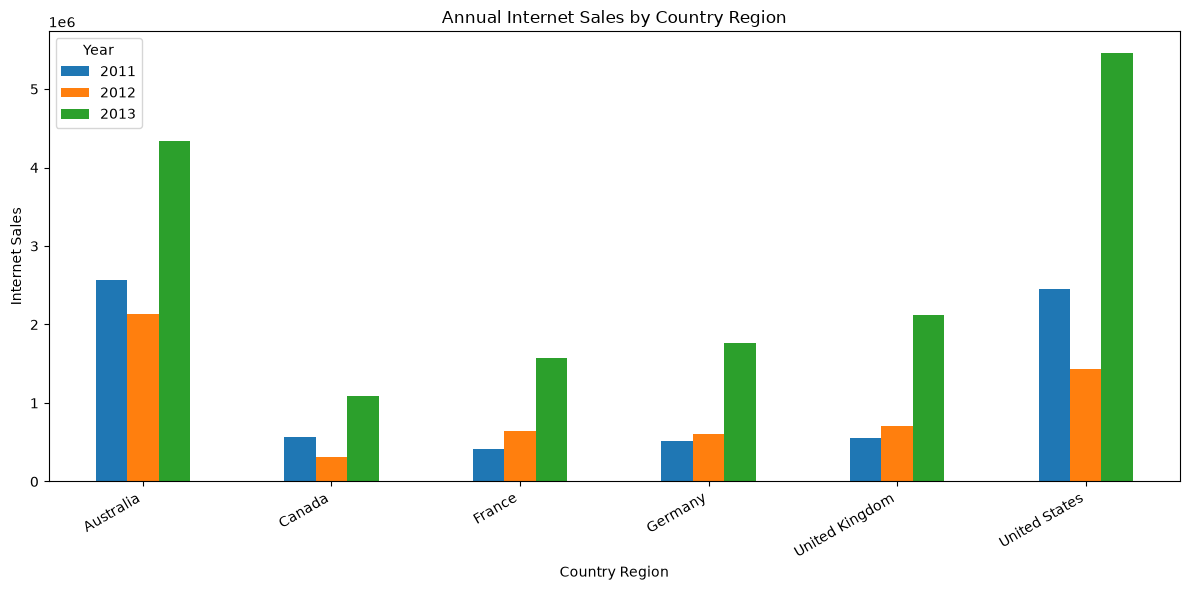

In [65]:
sales_pivot = yearly_sales_new.pivot(
    index="Country Region",
    columns="Year",
    values="SalesAmount")

sales_pivot.plot(kind="bar", figsize=(12, 6))

plt.xlabel("Country Region")
plt.ylabel("Internet Sales")
plt.title("Annual Internet Sales by Country Region")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Year")
plt.tight_layout()
plt.show()

# The United States and Australia are the markets with high Internet sales from
# 2011 to 2013.

In [66]:
# 1.2 Monthly Sales Patterns and Potential Seasonality

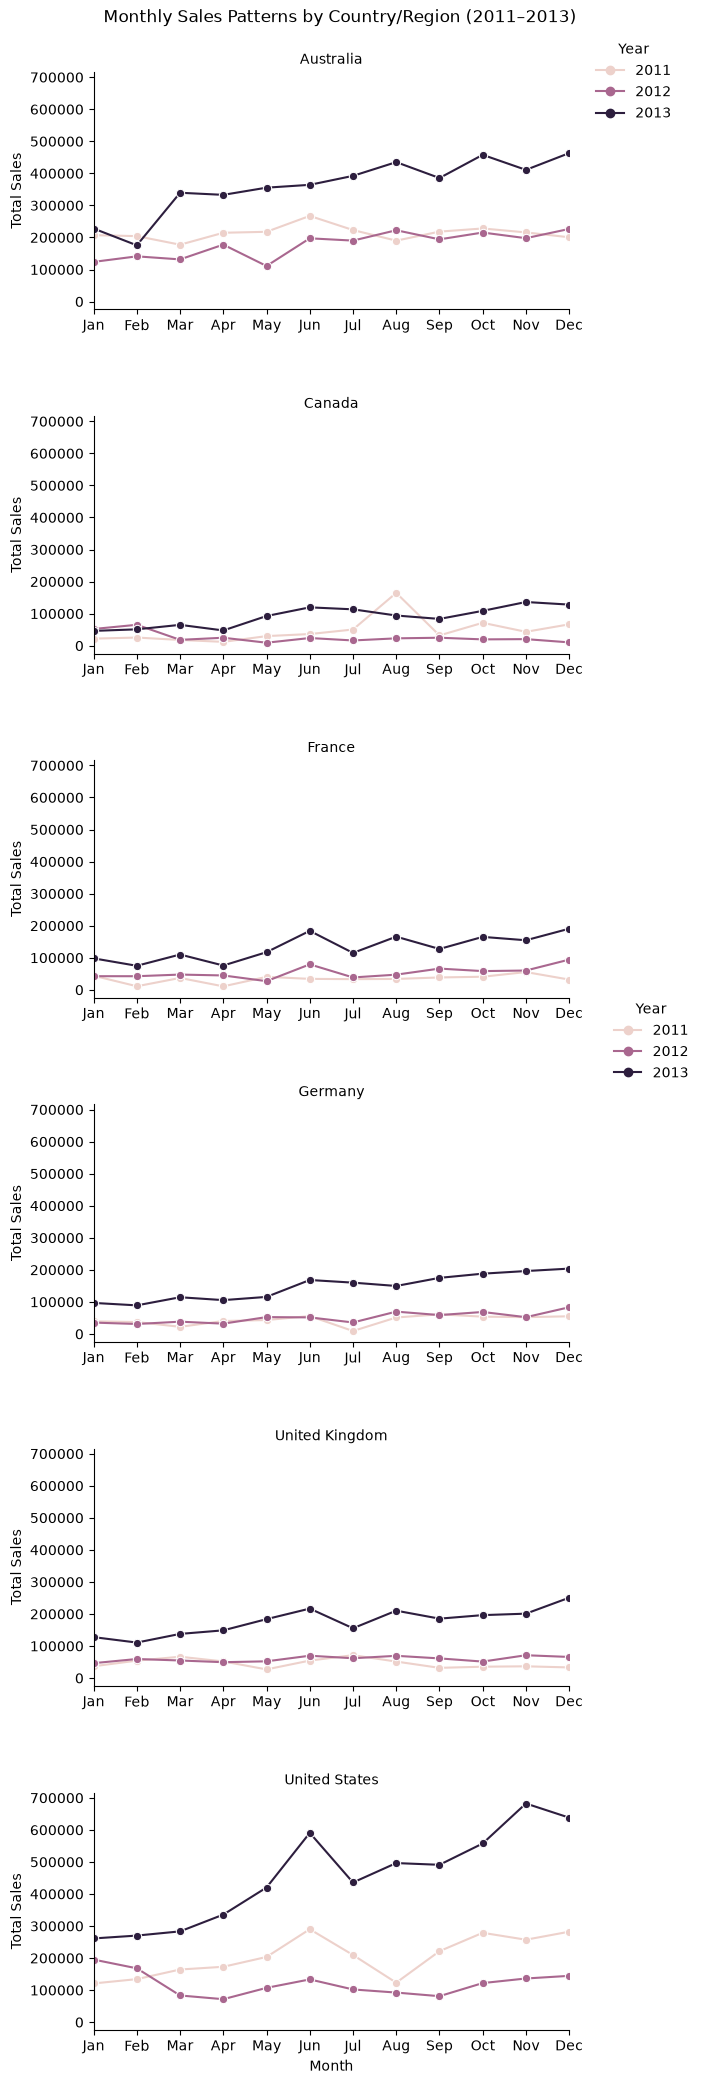

In [67]:
# Keep complete years only to ensure fair monthly comparisons
complete_years_df = df[
    df["OrderDate"].dt.year.isin([2011, 2012, 2013])].copy()

complete_years_df["Year"] = complete_years_df["OrderDate"].dt.year
complete_years_df["Month"] = complete_years_df["OrderDate"].dt.month

monthly_sales_by_country = (
    complete_years_df
    .groupby(
        ["EnglishCountryRegionName", "Year", "Month"],
        as_index=False)
    .agg(MonthlySales=("SalesAmount", "sum")))

g = sns.relplot(
    data=monthly_sales_by_country,
    x="Month",
    y="MonthlySales",
    hue="Year",
    col="EnglishCountryRegionName",
    col_wrap=1,
    kind="line",
    marker="o",
    height=3.5,
    aspect=1.8)

g.set_axis_labels("Month", "Total Sales")
g.set_titles("{col_name}")
g.set(xlim=(1, 12), xticks=range(1, 13))

for ax in g.axes.flat:
    ax.tick_params(axis="x", labelbottom=True)
    ax.set_xticklabels(
        ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
         "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
        rotation=0)

g.figure.subplots_adjust(
    right=0.82,
    top=0.96,
    hspace=0.45)

handles, labels = g.axes.flat[0].get_legend_handles_labels()

g.figure.legend(
    handles,
    labels,
    title="Year",
    loc="upper right",
    bbox_to_anchor=(0.98, 0.98),
    bbox_transform=g.figure.transFigure,
    frameon=False)

g.figure.suptitle(
    "Monthly Sales Patterns by Country/Region (2011–2013)",
    y=0.99)

plt.show()

# Australia: Monthly sales in 2013 were generally higher than
# in the previous two years, showing an overall upward trend,
# with higher sales toward the end of the year.

# Canada: Sales were relatively low compared with other
# countries. Most monthly sales in 2013 were higher than
# those in the previous two years. A notable sales peak
# occurred in August 2011.

# France: Sales in 2013 were generally higher than in the
# previous two years and showed an overall upward trend,
# although monthly fluctuations were considerable.
# Sales in June and December were relatively high in both
# 2012 and 2013.

# Germany: Sales in 2013 were generally higher than in the
# previous two years. The overall trend was relatively
# stable, with a slight increase during the second half of
# the year.

# United Kingdom: Sales in 2013 were generally higher than
# in the previous two years, with relatively high sales
# toward the end of the year.

# United States: Monthly sales in 2013 were clearly higher
# than in the previous two years, showing an overall upward
# trend. Sales were relatively high in June and November,
# although the pattern varied across years.

# Overall, most countries recorded higher monthly sales in
# 2013 than in the previous two years, but sales trends and
# peak months varied across markets.
# For example, Australia and United Kingdom had
# relatively high sales toward the end of the year, while
# United States recorded relatively high sales in June and
# November. These patterns suggest that sales trends may
# differ across markets. However, three years of data are
# insufficient to determine whether these patterns reflect
# consistent seasonality.

# Question 2: How do customers’ yearly income and gender distributions vary across country regions?

In [68]:
# The dataset contains multiple sales records for the same customer.
# Therefore, to accurately summarize Yearly Income and Gender across
# country regions, duplicate customer records should be removed based on
# the unique customer identifier ('CustomerKey').
# This ensures that each customer is counted only once, preventing customers
# with more purchase records from being overrepresented in the summary statistics.

customer_df = df.drop_duplicates(subset="CustomerKey").copy()
pd.set_option("display.max_columns", None)

customer_df.groupby("EnglishCountryRegionName")["YearlyIncome"].agg(
    ["count", "mean", "median", "std", "min", "max"])

# Australia has the highest mean yearly income ($64,338.62), closely
# followed by the United States ($63,616.83), while France has the
# lowest mean ($35,762.43).

# United Kingdom has the largest standard deviation ($48,431.99),
# indicating the greatest variability in yearly income. Canada has
# the smallest standard deviation ($20,251.52), indicating the least
# variability.

# The income range is largest in Australia, Canada, the United Kingdom,
# and the United States ($160,000), while France has the smallest range
# ($100,000). All regions have the same minimum yearly income ($10,000).

,count,mean,median,std,min,max
EnglishCountryRegionName,,,,,,
Australia,3591,64338.62,70000.00,31830.00,10000,170000
Canada,1571,57167.41,60000.00,20251.52,10000,170000
France,1810,35762.43,30000.00,27277.40,10000,110000
Germany,1780,42943.82,30000.00,35493.58,10000,130000
United Kingdom,1913,52169.37,30000.00,48431.99,10000,170000
United States,7819,63616.83,60000.00,25706.48,10000,170000


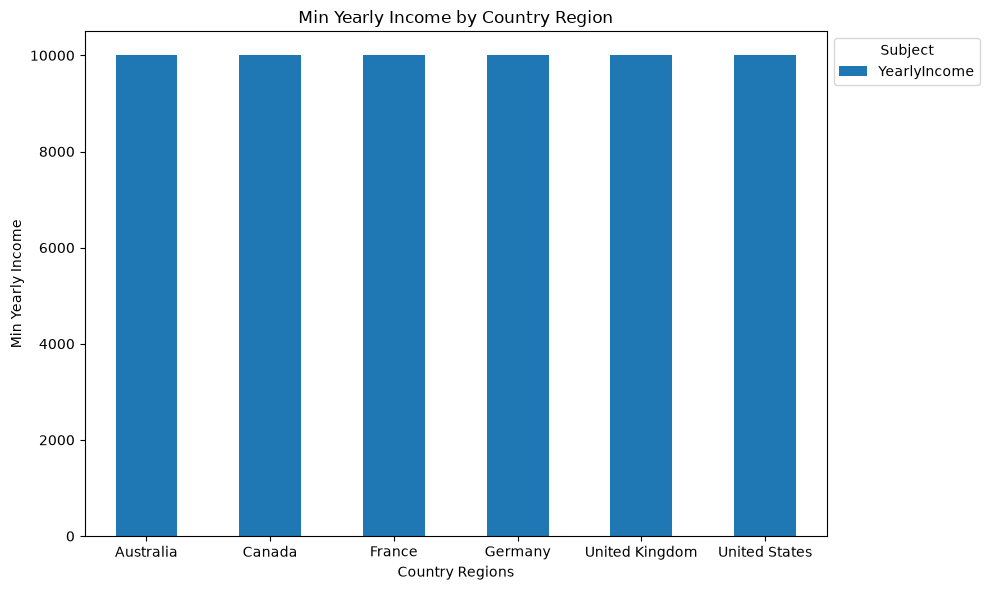

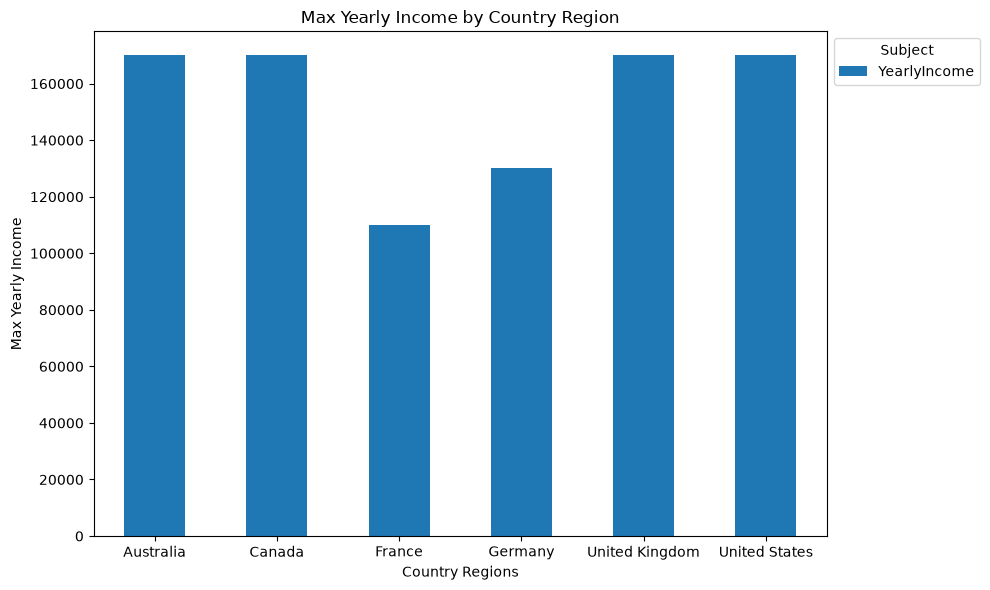

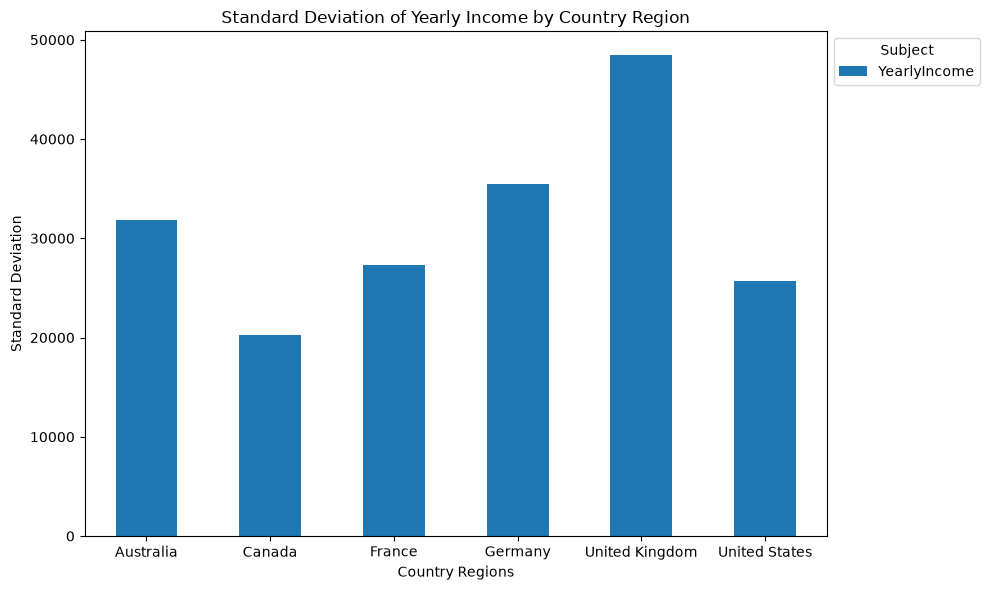

In [69]:
# Bar chart
customer_df.groupby("EnglishCountryRegionName")[
    ["YearlyIncome"]
].min().plot(kind='bar', figsize=(10, 6))

plt.xlabel("Country Regions")
plt.ylabel("Min Yearly Income")
plt.title("Min Yearly Income by Country Region")
plt.legend(title="Subject", bbox_to_anchor=(1, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


customer_df.groupby("EnglishCountryRegionName")[
    ["YearlyIncome"]
].max().plot(kind='bar', figsize=(10, 6))

plt.xlabel("Country Regions")
plt.ylabel("Max Yearly Income")
plt.title("Max Yearly Income by Country Region")
plt.legend(title="Subject", bbox_to_anchor=(1, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


customer_df.groupby("EnglishCountryRegionName")[
    ["YearlyIncome"]
].std().plot(kind='bar', figsize=(10, 6))

plt.xlabel("Country Regions")
plt.ylabel("Standard Deviation")
plt.title("Standard Deviation of Yearly Income by Country Region")
plt.legend(title="Subject", bbox_to_anchor=(1, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

<Figure size 1000x600 with 0 Axes>

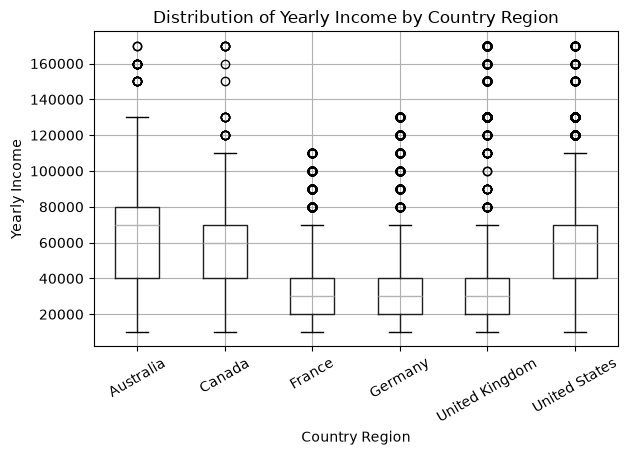

In [70]:
plt.figure(figsize=(10, 6))

customer_df.boxplot(
    column="YearlyIncome",
    by="EnglishCountryRegionName",
    rot=30)

plt.title("Distribution of Yearly Income by Country Region")
plt.suptitle("")
plt.xlabel("Country Region")
plt.ylabel("Yearly Income")
plt.tight_layout()
plt.show()

# The boxplots are used to compare the distributions of yearly income
# across country regions and identify potential outliers and differences
# in spread and median income. Q-Q plots are used to further assess
# normality within each region.

In [71]:
# Normality: Shapiro-Wilk test
from scipy.stats import shapiro

def check_normality(data, group_var, outcome_var):
    print(f"\nNormality: {outcome_var} by {group_var}")

    for group in data[group_var].dropna().unique():
        values = data.loc[data[group_var] == group, outcome_var].dropna()

        stat, p = shapiro(values)

        print(f"{group}: N={len(values)}, " f"W={stat:.4f}, p={p:.4g}")

check_normality(customer_df, 'EnglishCountryRegionName', 'YearlyIncome')


Normality: YearlyIncome by EnglishCountryRegionName
Australia: N=3591, W=0.9556, p=9.22e-32
United States: N=7819, W=0.9023, p=4.224e-57
Canada: N=1571, W=0.9230, p=1.307e-27
Germany: N=1780, W=0.7568, p=2.582e-45
United Kingdom: N=1913, W=0.7261, p=1.762e-48
France: N=1810, W=0.7845, p=9.799e-44


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 7819.
  res = hypotest_fun_out(*samples, **kwds)


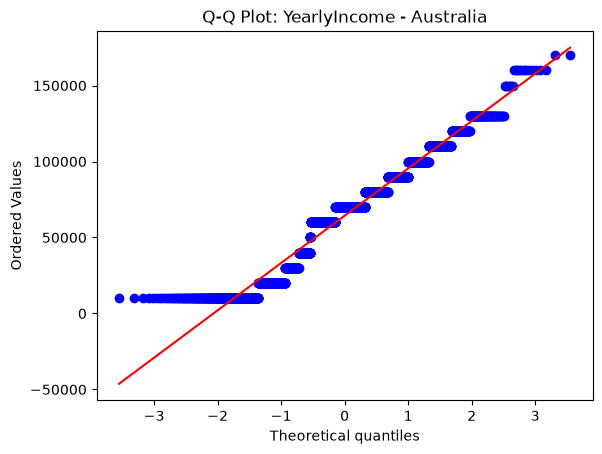

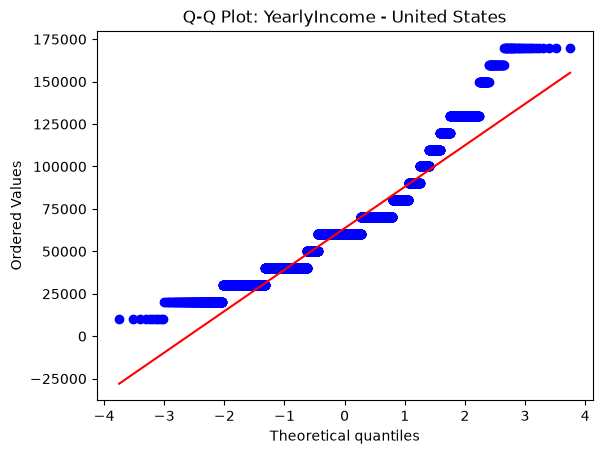

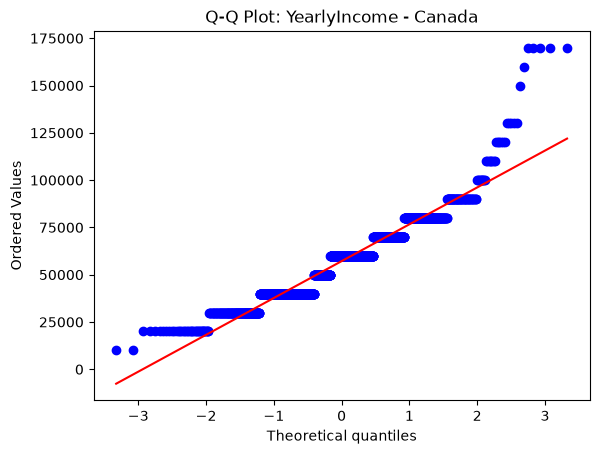

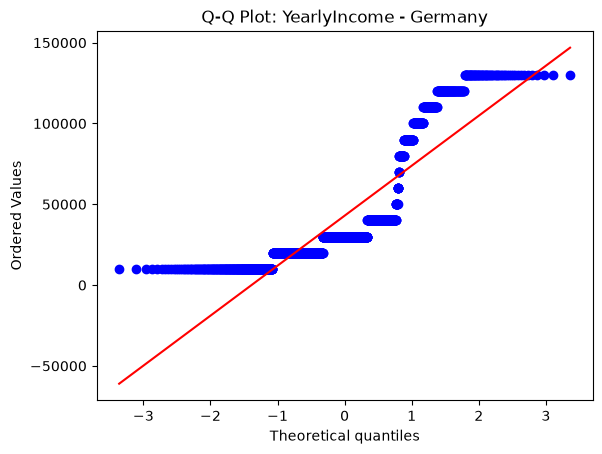

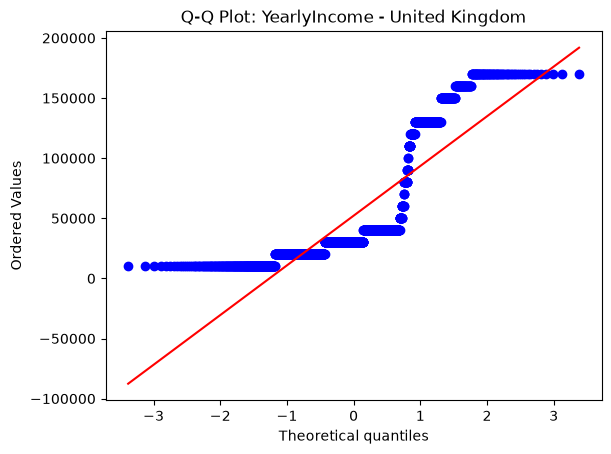

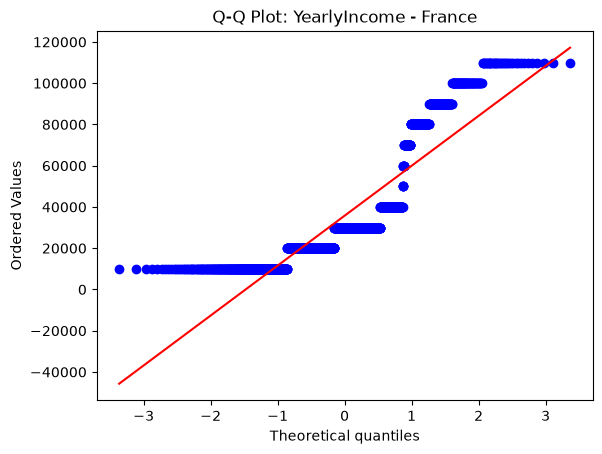

In [72]:
# Normality: Q-Q plots
def plot_qq(data, group_var, outcome_var):
    for group in data[group_var].dropna().unique():
        values = data.loc[data[group_var] == group, outcome_var].dropna()

        stats.probplot(values, dist="norm", plot=plt)
        plt.title(f"Q-Q Plot: {outcome_var} - {group}")
        plt.show()

plot_qq(customer_df, 'EnglishCountryRegionName', 'YearlyIncome')

# Normality is assessed using the Shapiro-Wilk test and Q-Q plots. The
# Shapiro-Wilk test indicates statistically significant deviations from
# normality across all six country regions (p < .001). However,
# given the large sample sizes and the sensitivity of the Shapiro-Wilk test
# to small deviations from normality, Q-Q plots are also examined. The
# Q-Q plots show noticeable and systematic deviations from the theoretical
# normal line. Overall, the results suggest that the normality assumption is
# not fully satisfied, although the large sample sizes may reduce the impact
# of this violation on the analysis.

In [73]:
# Homogeneity of variance
from scipy.stats import levene

groups = [
    group['YearlyIncome'].dropna()
    for name, group in customer_df.groupby('EnglishCountryRegionName')]

stat, p = levene(*groups, center='median')

print("Levene's statistic =", stat)
print("p-value =", p)
# Levene's test is statistically significant, F = 140.87, p < .001,
# indicating that the variances of YearlyIncome differs significantly across the
# six country regions. Therefore, the homogeneity of variance
# assumption is not supported.

Levene's statistic = 140.86720740880875
p-value = 3.735482467792036e-147


In [74]:
# To determine whether there is a statistically significant difference
# in customers' yearly income across six country regions, an ANOVA is conducted.
# Because the homogeneity of variance assumption is not supported,
# Welch's ANOVA is used instead of the conventional one-way ANOVA,
# followed by the Games-Howell post-hoc test.

!pip install pingouin
import pingouin as pg
pg.welch_anova(data=customer_df, dv='YearlyIncome', between='EnglishCountryRegionName')

# Welch's ANOVA indicates a statistically significant difference in
# customers' yearly income across six country regions,
# F(5, 5517.03) = 413.40, p < .001, partial η² = .09.

,Source,ddof1,ddof2,F,p_unc,np2
0,EnglishCountryRegionName,5,5517.03,413.40,0.00,0.09


In [75]:
# Games-Howell post-hoc
pg.pairwise_gameshowell(data=customer_df, dv='YearlyIncome', between='EnglishCountryRegionName')

# Games-Howell post-hoc comparisons show that mean yearly income
# differs significantly across most country regions (p < .001), except
# for the comparison between Australia and the United States
# (mean difference = 721.79, p = .84, Hedges' g = 0.03).


,A,B,mean_A,mean_B,diff,se,T,df,pval,hedges
0,Australia,Canada,64338.62,57167.41,7171.22,737.02,9.73,4499.13,0.00,0.25
1,Australia,France,64338.62,35762.43,28576.19,832.60,34.32,4157.44,0.00,0.94
2,Australia,Germany,64338.62,42943.82,21394.80,994.93,21.50,3226.02,0.00,0.65
3,Australia,United Kingdom,64338.62,52169.37,12169.26,1228.13,9.91,2813.77,0.00,0.32
4,Australia,United States,64338.62,63616.83,721.79,605.52,1.19,5823.01,0.84,0.03
5,Canada,France,57167.41,35762.43,21404.98,819.84,26.11,3301.86,0.00,0.88
6,Canada,Germany,57167.41,42943.82,14223.59,984.28,14.45,2888.18,0.00,0.48
7,Canada,United Kingdom,57167.41,52169.37,4998.04,1219.52,4.10,2665.67,0.00,0.13
8,Canada,United States,57167.41,63616.83,-6449.42,587.86,-10.97,2694.38,0.00,-0.26
9,France,Germany,35762.43,42943.82,-7181.39,1057.75,-6.79,3338.24,0.00,-0.23


In [76]:
# Gender counts by country
customer_df = df.drop_duplicates(subset="CustomerKey").copy()
gender_summary = customer_df.groupby("EnglishCountryRegionName").agg(
    Total_Count=("Gender", "count"),
    Min=("Gender", "min"),
    Max=("Gender", "max"),
    Female_Count=("Gender", lambda x: (x == "F").sum()),
    Male_Count=("Gender", lambda x: (x == "M").sum()))

gender_summary["Female_Percentage"] = (
    gender_summary["Female_Count"] / gender_summary["Total_Count"] * 100
).round(2)

gender_summary["Male_Percentage"] = (
    gender_summary["Male_Count"] / gender_summary["Total_Count"] * 100
).round(2)

display(gender_summary)

# Instead of standard deviation, proportions are used to
# describe gender distribution because proportions provide
# a more intuitive interpretation of the relative
# representation of each gender within each country.

,Total_Count,Min,Max,Female_Count,Male_Count,Female_Percentage,Male_Percentage
EnglishCountryRegionName,,,,,,,
Australia,3591,F,M,1777,1814,49.48,50.52
Canada,1571,F,M,767,804,48.82,51.18
France,1810,F,M,893,917,49.34,50.66
Germany,1780,F,M,874,906,49.10,50.90
United Kingdom,1913,F,M,934,979,48.82,51.18
United States,7819,F,M,3888,3931,49.73,50.27


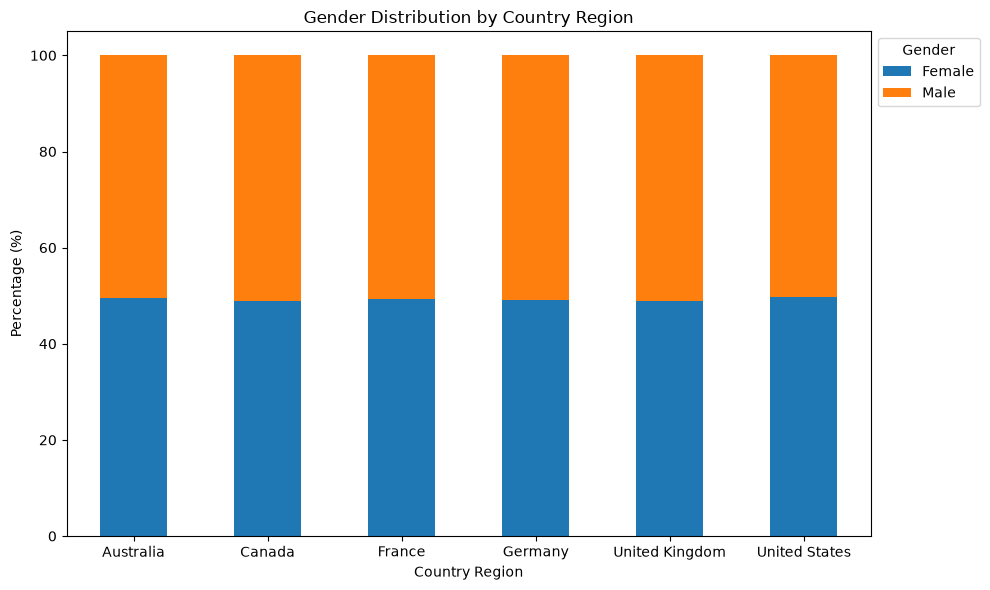

In [77]:
gender_summary[["Female_Percentage", "Male_Percentage"]
].plot(kind="bar", stacked=True, figsize=(10, 6))

plt.xlabel("Country Region")
plt.ylabel("Percentage (%)")
plt.title("Gender Distribution by Country Region")
plt.legend(["Female", "Male"], title="Gender", bbox_to_anchor=(1, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
# Gender distribution is relatively balanced across all countries,
# with approximately 50% female and 50% male customers.

In [78]:
# Chi-square test is used to examine whether gender distribution
# is significantly associated with country region.
from scipy.stats import chi2_contingency

gender_table = pd.crosstab(
    customer_df["EnglishCountryRegionName"],
    customer_df["Gender"])

chi2, p, dof, expected = chi2_contingency(gender_table)

print("Chi-square statistic:", chi2)
print("p-value:", p)
print("Degrees of freedom:", dof)

# The chi-square test of independence found no statistically
# significant association between gender and country region
# (chi-square = .87, df = 5, p = .97).
# This suggests that the gender distribution does not differ
# significantly across country regions in this sample.

Chi-square statistic: 0.8702178504063985
p-value: 0.9723401612420225
Degrees of freedom: 5


In [79]:
# Cramér’s V

chi2 = 0.8702178504063985
n = gender_table.to_numpy().sum()
r, c = gender_table.shape

cramers_v = np.sqrt(chi2 / (n * min(r - 1, c - 1)))

print("Cramér's V:", cramers_v)

# Cramér's V was .007, indicating a negligible association between
# the two variables. These results suggest that the gender distribution
# is highly similar across country regions in this dataset.

Cramér's V: 0.006861451752180472


# Question 3: Which product category generates the highest total sales, and what is the average price of that category?

In [80]:
print(
    "Product name:",
    df["EnglishProductName"].unique())


Product name: <ArrowStringArray>
[       'Mountain-100 Silver, 38',        'Mountain-200 Silver, 38',
          'Fender Set - Mountain',          'Touring-1000 Blue, 46',
                   'Touring Tire',              'Touring Tire Tube',
          'Sport-100 Helmet, Red', 'Short-Sleeve Classic Jersey, S',
          'Water Bottle - 30 oz.',           'Mountain Bottle Cage',
 ...
             'Road-650 Black, 58',             'Road-650 Black, 44',
               'Road-650 Red, 52',               'Road-650 Red, 60',
             'Road-650 Black, 48',               'Road-650 Red, 44',
             'Road-650 Black, 60',               'Road-650 Red, 58',
             'Road-650 Black, 52',               'Road-650 Red, 62']
Length: 130, dtype: str


In [81]:
def categorize_product(name):
    name = name.lower()

    # Clothing
    if any(keyword in name for keyword in [
        "jersey", "shorts", "gloves", "socks", "vest", "cap"]):
        return "Clothing"

    # Accessories
    elif any(keyword in name for keyword in [
        "helmet", "tire", "tube", "bottle", "cage",
        "fender", "patch kit", "bike stand", "rack",
        "hydration pack", "bike wash"]):
        return "Accessories"

    # Bikes
    elif any(keyword in name for keyword in [
        "mountain-", "road-", "touring-"]):
        return "Bikes"

    # Products that do not match the rules
    else:
        return "Other"


df["ProductCategory"] = df["EnglishProductName"].apply(categorize_product)

display(
    df[["EnglishProductName", "ProductCategory"]]
    .drop_duplicates()
    .sort_values("ProductCategory"))

,EnglishProductName,ProductCategory
2,Fender Set - Mountain,Accessories
4,Touring Tire,Accessories
5,Touring Tire Tube,Accessories
6,"Sport-100 Helmet, Red",Accessories
10,Water Bottle - 30 oz.,Accessories
...,...,...
301,"Classic Vest, L",Clothing
480,"Long-Sleeve Logo Jersey, M",Clothing
493,"Women's Mountain Shorts, S",Clothing
948,"Long-Sleeve Logo Jersey, XL",Clothing


In [82]:
category_counts = df.groupby("ProductCategory").size()

display(category_counts)

ProductCategory
Accessories    36092
Bikes          15205
Clothing        9101
dtype: int64

In [83]:
category_summary = df.groupby("ProductCategory").agg(
    Total_Sales=("SalesAmount", "sum"),
    Average_Price=("UnitPrice", "mean"),
    Product_Count=("EnglishProductName", "nunique"),
    Transaction_Count=("ID", "count")
).sort_values("Total_Sales", ascending=False)

display(category_summary)
# So, Bikes category generates the most sales, and the average price is $1862.42.

,Total_Sales,Average_Price,Product_Count,Transaction_Count
ProductCategory,,,,
Bikes,28318144.65,1862.42,88,15205
Accessories,700759.96,19.42,22,36092
Clothing,339772.61,37.33,20,9101


# Question 4: Is there a statistically significant difference in total customer sales between homeowners and non-homeowners?


In [84]:
# The dataset contains multiple sales records for the same customer.
# Therefore, to accurately examine the influence of house ownership on sals amount,
# duplicate customer records should be removed based on
# the unique customer identifier ('CustomerKey').

customer_sales = (
    df.groupby(["CustomerKey", "HouseOwnerFlag"],
        as_index=False).agg(
        TotalSales=("SalesAmount", "sum"),
        OrderLines=("ID", "count")))

display(
    customer_sales.groupby("HouseOwnerFlag")["TotalSales"]
    .agg(["count", "mean", "median", "std", "min", "max"]))

,count,mean,median,std,min,max
HouseOwnerFlag,,,,,,
0,5982,1500.05,209.96,2046.88,2.29,13265.99
1,12502,1630.57,342.00,2159.07,2.29,13295.38


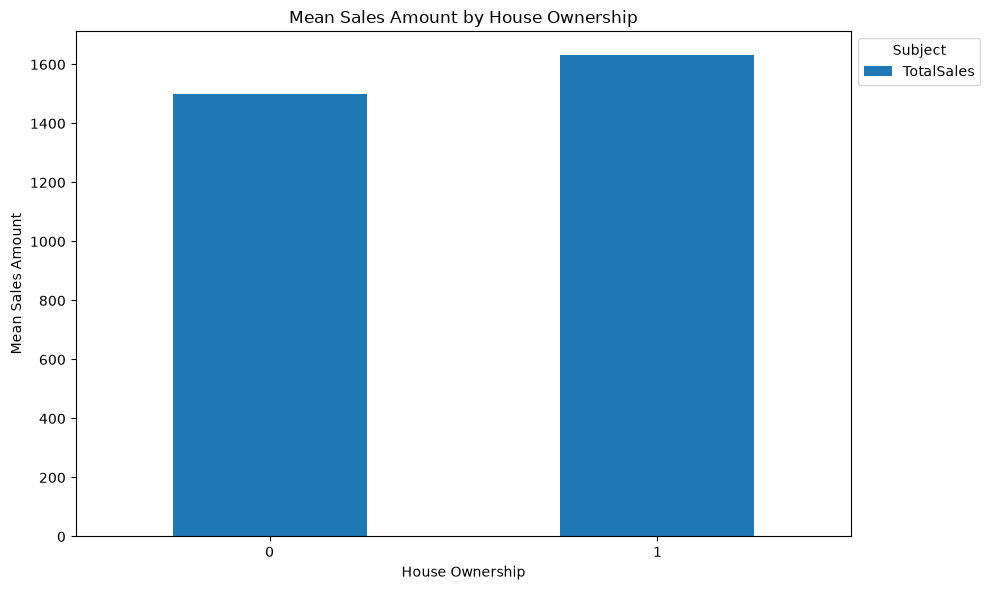

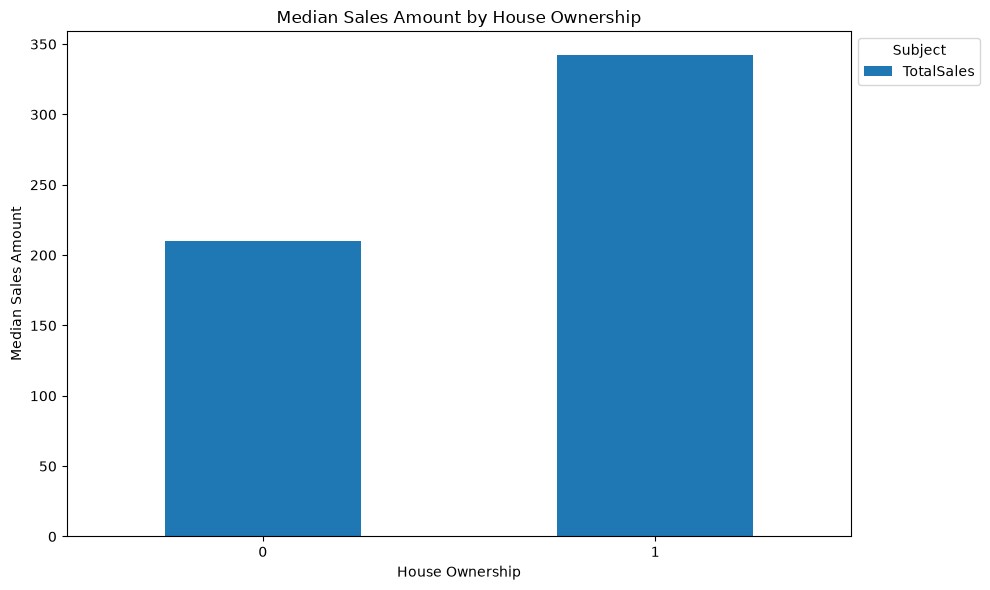

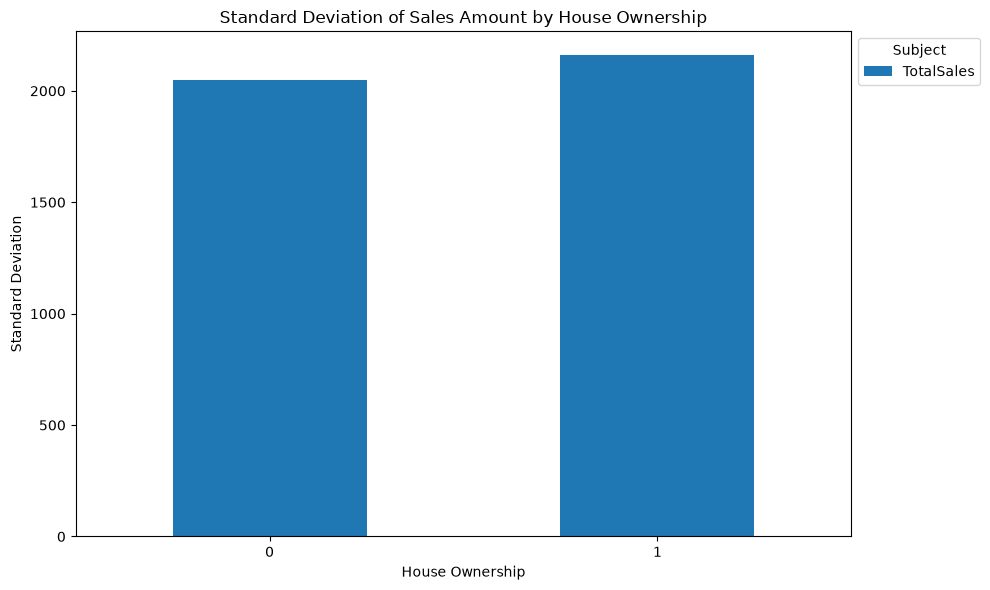

In [85]:
# Bar chart
customer_sales.groupby("HouseOwnerFlag")[
    ["TotalSales"]
].mean().plot(kind='bar', figsize=(10, 6))

plt.xlabel("House Ownership")
plt.ylabel("Mean Sales Amount")
plt.title("Mean Sales Amount by House Ownership")
plt.legend(title="Subject", bbox_to_anchor=(1, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


customer_sales.groupby("HouseOwnerFlag")[
    ["TotalSales"]
].median().plot(kind='bar', figsize=(10, 6))

plt.xlabel("House Ownership")
plt.ylabel("Median Sales Amount")
plt.title("Median Sales Amount by House Ownership")
plt.legend(title="Subject", bbox_to_anchor=(1, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


customer_sales.groupby("HouseOwnerFlag")[
    ["TotalSales"]
].std().plot(kind='bar', figsize=(10, 6))

plt.xlabel("House Ownership")
plt.ylabel("Standard Deviation")
plt.title("Standard Deviation of Sales Amount by House Ownership")
plt.legend(title="Subject", bbox_to_anchor=(1, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

<Figure size 800x500 with 0 Axes>

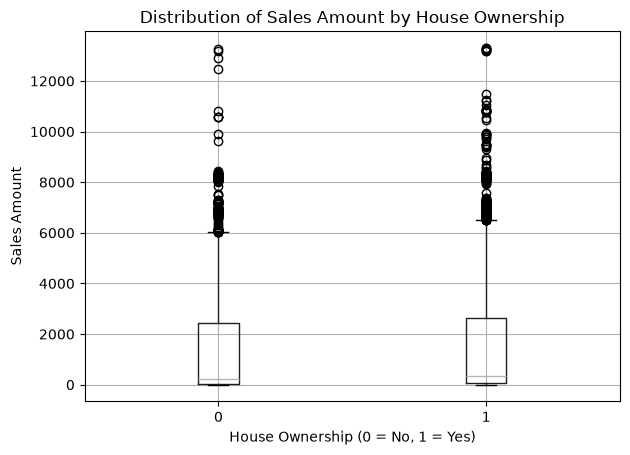

In [86]:
plt.figure(figsize=(8, 5))

customer_sales.boxplot(
    column="TotalSales",
    by="HouseOwnerFlag"
)

plt.title("Distribution of Sales Amount by House Ownership")
plt.suptitle("")
plt.xlabel("House Ownership (0 = No, 1 = Yes)")
plt.ylabel("Sales Amount")
plt.tight_layout()
plt.show()
# The boxplots show some potential outliers and a certain degree of tail deviation.
# Therefore, both mean and median are examined, and Q-Q plots are used
# to further assess distribution of scores.


Normality: TotalSales by HouseOwnerFlag
1: N=12502, W=0.7671, p=4.05e-85
0: N=5982, W=0.7542, p=1.998e-69


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 12502.
  res = hypotest_fun_out(*samples, **kwds)
/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5982.
  res = hypotest_fun_out(*samples, **kwds)


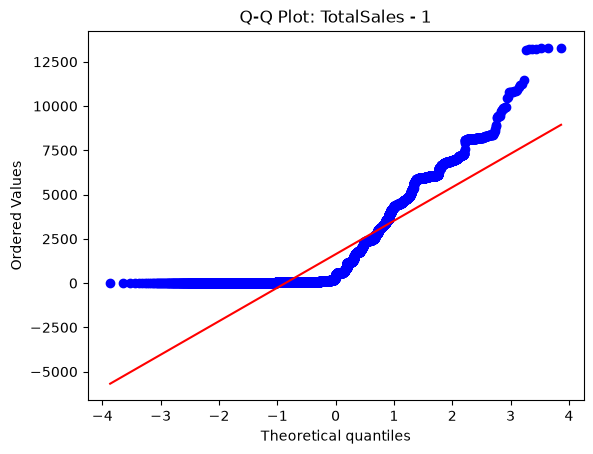

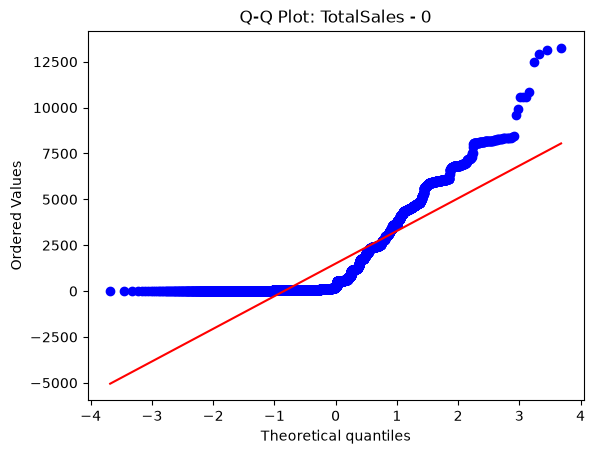

In [87]:
# Normality: Shapiro-Wilk test
from scipy.stats import shapiro

def check_normality(data, group_var, outcome_var):
    print(f"\nNormality: {outcome_var} by {group_var}")

    for group in data[group_var].dropna().unique():
        values = data.loc[data[group_var] == group, outcome_var].dropna()

        stat, p = shapiro(values)

        print(f"{group}: N={len(values)}, " f"W={stat:.4f}, p={p:.4g}")
check_normality(customer_sales, 'HouseOwnerFlag', 'TotalSales')

def plot_qq(data, group_var, outcome_var):
    for group in data[group_var].dropna().unique():
        values = data.loc[data[group_var] == group, outcome_var].dropna()

        stats.probplot(values, dist="norm", plot=plt)
        plt.title(f"Q-Q Plot: {outcome_var} - {group}")
        plt.show()
plot_qq(customer_sales, 'HouseOwnerFlag', 'TotalSales')

# Normality is assessed using the Shapiro-Wilk test and Q-Q plots. The
# Shapiro-Wilk test indicates statistically significant deviations from
# normality across two house ownership groups (p < .001). However,
# given the large sample sizes and the sensitivity of the Shapiro-Wilk test
# to small deviations from normality, Q-Q plots are also examined. The
# Q-Q plots show noticeable and systematic deviations from the theoretical
# normal line. Overall, the results suggest that the normality assumption is
# not fully satisfied, although the large sample sizes may reduce the impact
# of this violation on the analysis.

In [88]:
# Homogeneity of variance
from scipy.stats import levene

groups = [group['TotalSales'].dropna()
    for name, group in customer_sales.groupby('HouseOwnerFlag')]

stat, p = levene(*groups)

print("Levene's statistic =", stat)
print("p-value =", p)
# Levene's test is statistically significant (p < .001),
# indicating that the variances of customer-level sales
# differ between homeowners and non-homeowners.
# Therefore, the equal-variance assumption is not supported.

Levene's statistic = 16.24815675288312
p-value = 5.578629081379288e-05


In [89]:
# Welch's t-test is further applied to examine whether the difference
# in sales amount between two house ownership groups is significant
from scipy.stats import ttest_ind

homeowners = customer_sales.loc[
    customer_sales["HouseOwnerFlag"] == 1, "TotalSales"].dropna()

non_homeowners = customer_sales.loc[
    customer_sales["HouseOwnerFlag"] == 0, "TotalSales"].dropna()

t_stat, p_value = ttest_ind(
    homeowners,
    non_homeowners,
    equal_var=False)

print(f"t = {t_stat:.4f}, p = {p_value:.4g}")
# The Welch's t-test shows a t-statistic of 3.98 (p < .001),
# indicating that this analysis provides sufficient evidence
# of a difference in mean sales amount between the two groups.

t = 3.9838, p = 6.82e-05


In [90]:
# Cohen's d
n1, n2 = len(homeowners), len(non_homeowners)
s1, s2 = homeowners.std(ddof=1), non_homeowners.std(ddof=1)

pooled_sd = np.sqrt(
    ((n1 - 1) * s1**2 + (n2 - 1) * s2**2)
    / (n1 + n2 - 2))

cohens_d = (homeowners.mean() - non_homeowners.mean()) / pooled_sd

print(f"Cohen's d = {cohens_d:.4f}")
# Although Welch's t-test indicates a statistically significant difference
# in mean customer-level sales between homeowners and non-homeowners,
# the small Cohen's d (0.06) suggests that the difference is negligible
# in magnitude. This may partly be due to the relatively large sample size,
# which reduces the standard error and increases the likelihood of detecting
# small differences as statistically significant.

Cohen's d = 0.0615


In [91]:
# Because sales amount distributions appeared to deviate from normality,
# Mann–Whitney U test is also conducted.

from scipy.stats import mannwhitneyu

U, p = mannwhitneyu(homeowners, non_homeowners, alternative="two-sided")

n1 = len(homeowners)
n2 = len(non_homeowners)

rank_biserial = 1 - (2 * U) / (n1 * n2)

print("U-statistic:", U)
print("p-value:", p)
print("Rank-biserial correlation:", rank_biserial)

# The Mann–Whitney U test found a statistically significant difference
# in sales amount distributions between homeowners and non-homeowners,
# U = 38,559,853, p < .001. However, the rank-biserial correlation
# (r = -0.031) indicates a negligible effect size.
# Both Welch's t-test and the Mann–Whitney U test found statistically
# significant differences between homeowners and non-homeowners.
# The Welch's t-test suggests a difference in their mean sales amounts,
# while the Mann–Whitney U test suggests a difference in their sales
# distributions or ranks. However, Cohen's d and the rank-biserial
# correlation indicates that the magnitude of these differences is very small.

U-statistic: 38559853.0
p-value: 0.0005892944434267559
Rank-biserial correlation: -0.031191826425792657
